# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": float(round(df["rating"].isna().mean() * 100, 1)),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': 27.6,
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


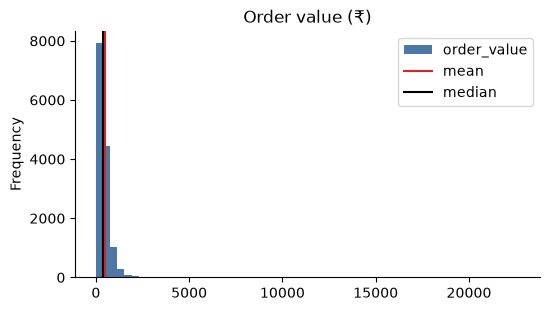

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

In [5]:
# Extra check (mine): is a missing rating linked to slow delivery? And does the delivery-time vs rating link differ by city?
print(df.groupby(df["rating"].isna())["delivery_minutes"].mean().round(1).rename("avg delivery minutes (False = rated, True = rating missing)"))
print()
print(df.dropna(subset=["rating"]).groupby("city")[["delivery_minutes", "rating"]].apply(lambda g: g["delivery_minutes"].corr(g["rating"])).round(2).rename("r (delivery minutes vs rating)"))

rating
False    22.9
True     23.0
Name: avg delivery minutes (False = rated, True = rating missing), dtype: float64

city
Bengaluru   -0.31
Hyderabad   -0.33
Pune        -0.32
Name: r (delivery minutes vs rating), dtype: float64


**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

**(a)** Insight 2 is the one affected. The mean order value is ₹465, but the median is only ₹358 and the skew is about 13, which is very high. The histogram has a long tail on the right, so a small number of very big orders are pulling the average up. That means ₹465 is not what a normal customer spends. I would rewrite it as: *"A typical order is about ₹358 (the median). The average of ₹465 is pulled up by a small number of very large orders."* (I also removed 70 duplicate rows first, so these numbers are on the cleaned data.)

**(b)** 27.6% of the ratings are missing, and they are not missing evenly. Hyderabad is missing about 45% while Bengaluru and Pune are only about 21%. So insight 6 is built only on customers who bothered to rate, and Hyderabad is under-represented. If unhappy (or very happy) customers skip rating, the true link between delivery time and rating could be different from r = −0.32. In my extra check, orders with missing ratings were not slower (about 23 minutes in both groups) and r was about the same in all three cities (−0.31 to −0.33), so the risk looks small here. Still, the report should say "among rated orders" and mention the Hyderabad gap.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

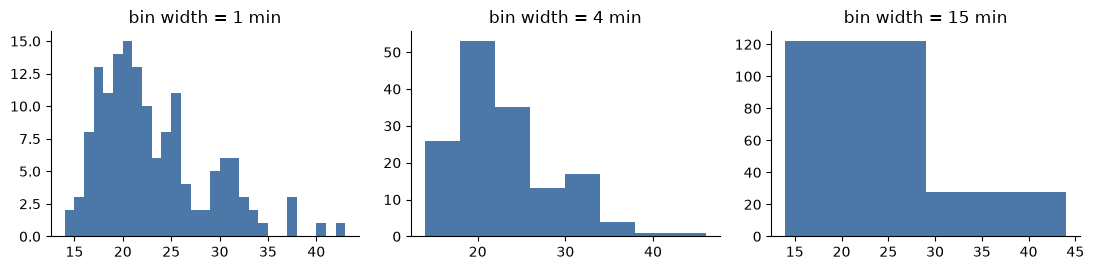

In [6]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False   # the 3 peaks vanish when the bins get wider
best_bin_width = 4   # 1 is too jumpy, 15 hides everything, 4 shows one main peak with a right tail

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

Before accepting a shape claim like "multimodal", I should redraw the histogram with a few different bin widths and see if the shape survives. Here the 1-minute bins look bumpy with several small peaks, because 150 orders are spread over too many tiny bins. With 4-minute bins there is one main peak and a tail to the right, and 15-minute bins are too wide and hide everything. So "three separate peaks" is just noise from the bin width, and I would choose 4 minutes.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


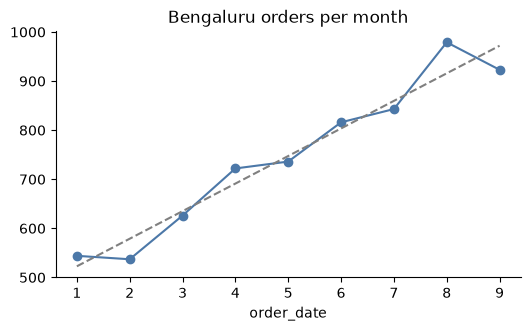

In [7]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


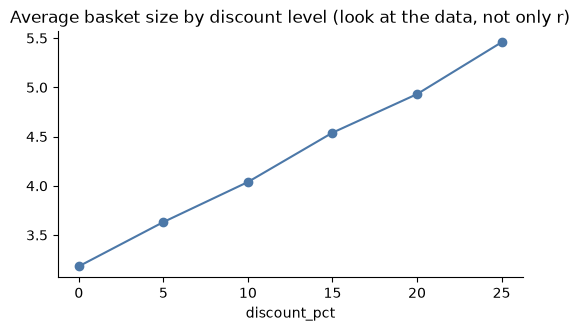

In [8]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [9]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

**(a)** The trend claim is reasonable. Bengaluru's monthly orders go up almost every month (544 to 923), the slope is about +56 orders per month, and Kendall's tau is 0.89 with p = 0.0002, so it is very unlikely to be random. But it is only 9 points, so I would not over-promise. I would show the actual monthly points as a line with the dashed trend line, and also point out that September dipped slightly from August (979 to 923). I would not extend the line into the future.

**(b)** Yes, the chart supports "move together". The average basket goes up steadily with each discount step, from about 3.2 items at 0% discount to about 5.5 items at 25%, and it looks close to a straight line, so r = 0.38 is a fair summary. But the AI cannot say discounts *cause* bigger baskets. It could be the other way round (bigger baskets qualify for bigger discounts), or some other thing like the type of customer could drive both. We would need an experiment, like giving discounts to a random group, to claim cause.

**(c)** The most likely false alarm is **discount_pct vs loyalty_points** (r = −0.022). Two reasons: (1) its p-value (about 0.008) does not survive the Bonferroni threshold (0.05 / 21 = 0.0024), while the other four pairs do; (2) the correlation is tiny, it explains almost nothing (about 0.05% of the variation), and it shows up as "significant" only because we have nearly 14,000 orders. Also there is no business reason why a discount should lower loyalty points, and with 21 pairs we expect about 1 false alarm anyway.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

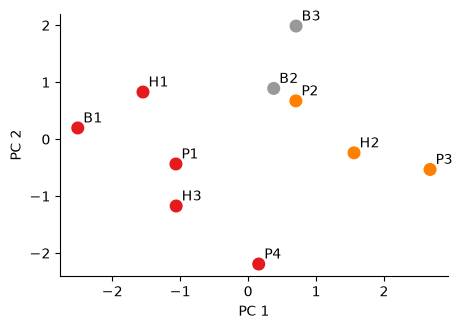

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [10]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

In [11]:
# Extra check (mine): are the 3 segments stable and well separated?
from sklearn.metrics import silhouette_score
for k in [2, 3, 4]:
    print(f"k = {k}: silhouette = {silhouette_score(Z, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)):.2f}")
for seed in range(3):
    print("one random start, seed", seed, "->", KMeans(n_clusters=3, n_init=1, random_state=seed).fit_predict(Z))
print(feats.round(2).agg(["min", "max"]))

k = 2: silhouette = 0.24
k = 3: silhouette = 0.21
k = 4: silhouette = 0.17
one random start, seed 0 -> [0 1 2 0 1 0 0 1 1 0]
one random start, seed 1 -> [2 0 0 1 0 1 1 0 0 1]
one random start, seed 2 -> [2 0 0 1 0 1 1 0 0 0]
     median_value  on_time  suburban_share  avg_discount  \
min         346.0     0.88            0.35          9.35   
max         373.0     0.92            0.48         10.01   

     orders_per_active_day  
min                    4.3  
max                    8.9  


**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*

With only 10 stores, each store is a single point, so k-means can easily cut a smooth spread into three groups that look like "types" but are not real. In my extra check the silhouette score is low (about 0.21), the stores look very similar on most features (median value ₹346–₹373, on-time 88–92%), and when I ran k-means with a single random start the groups changed. P3 and P4 also opened only in July (92 days of data), so their numbers are noisy. Before naming the segments I would check different values of k and different seeds, see which feature really separates the groups (it seems to be mostly orders per day and suburban share, maybe just the city), and ask the store managers if these groups make sense in real life.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [12]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] / hyd_month[8] - 1) * 100
first_test = "B"   # just counting rows per store per week; it checks the data before we believe any story

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [13]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]
culprit_store = weekly.tail(9).min().idxmin()   # store with the lowest weekly count (zero rows)

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


In [14]:
# Extra check (mine) for hypothesis C: did Hyderabad discounts change?
print(hyd.groupby(hyd["order_date"].dt.month)["discount_pct"].mean().round(2).loc[[8, 9]])

order_date
8    9.35
9    9.49
Name: discount_pct, dtype: float64


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

The data supported hypothesis **B** (a data problem): store H2 has zero rows from 5 to 25 September, which explains most of the drop. Hypothesis **A** is not supported because on-time % only changed by −0.3 points, and **C** is ruled out because the average discount stayed about the same (9.3% in August, 9.5% in September); **D** cannot be tested with this data.

**Corrected insight 4:** *"Hyderabad orders fell 28% from August to September (483 to 346), but most of this is because store H2 recorded no orders from 5 to 25 September, which looks like a data or system gap, so the cause needs to be confirmed with the store. On-time delivery barely changed (−0.3 points), so there is no evidence that service got worse. The other two stores together fell about 9.5%, which is worth watching."*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [15]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() / old[2].sum() - 1) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

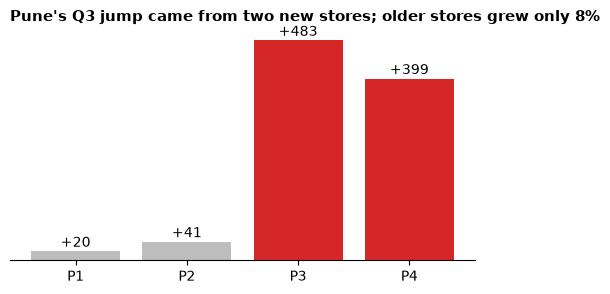

In [16]:
title = "Pune's Q3 jump came from two new stores; older stores grew only 8%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [17]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).round(1).unstack()
better_in_every_zone = "Partner A"
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

**(a)** *"Pune orders grew 117% from Q2 to Q3, but about half of the Q3 orders (882 of 1,746) came from two new stores, P3 and P4, that did not exist in Q2. The two older stores (P1, P2) grew only about 8% like-for-like. So the expansion added volume, but this is not the same as the business doubling. To call it a 'huge success' we would also need the cost of opening the new stores and to check if they took orders from the old ones."*

**(b)** Partner B looks better overall because it gets mostly **urban** orders (84% of its orders), and urban deliveries are shorter and easier. Partner A gets mostly **suburban** orders (67%), which are harder. When I compare inside each zone, Partner A is actually better in both: suburban 81.4% vs 72.0% and urban 98.8% vs 96.9%. This is Simpson's paradox. A careful human asks: *"Are the two partners being compared on the same kind of orders?"* If we sent everything to Partner B, the suburban deliveries would probably get worse.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [18]:
decisions = {
    1: "Accept",   # Bengaluru trend
    2: "Correct",   # average order value
    3: "Correct",   # Pune doubled
    4: "Correct",   # Hyderabad fell because service worsened
    5: "Reject",   # Partner B more punctual
    6: "Accept",   # delivery time vs rating
    7: "Accept",   # discount vs basket
    8: "Accept",   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: "Reject",   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = sum(v == "Accept" for v in decisions.values())
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*

I would call it an **assistant**, not a replacement. I accepted only 4 of 9 insights as stated, so precision is about 0.44 (more than half of the report needed a fix or rejection), and recall is about 0.57, so it also missed some true insights (for example the data gap and the zone effect were found by me, not by it). The wrong ones (4, 5, 9) looked confident and could lead to bad decisions, so a human must check them before they go to Meera.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [19]:
levels = {
    2: "data",   # "The average order value is ₹465."
    6: "between",   # "Longer delivery times go with lower ratings."
    9: "beyond",   # "Orders will recover in October."
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [20]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [21]:
threat = 'wrong problem'   # the numbers are right but they answer a different question than Meera's
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

**Insight 2 (rewritten):** *"The typical order is about ₹358 (median). The mean is ₹465, but it is pulled up by a small number of very large orders, so the median is a better summary."*

**Insight 4 (rewritten):** *"Hyderabad orders fell 28% from August to September (483 to 346), mainly because store H2 has no recorded orders from 5 to 25 September, which looks like a data or system gap. On-time delivery barely changed (−0.3 points) and discounts were the same, so the data gives no evidence that service got worse. The other two Hyderabad stores together fell about 9.5%."*

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*

I found **insight 5** (Partner B is 93% vs 87%, so send everything to B) the most convincing. It had two clean numbers, a clear action and confident wording, so it sounded like a finished decision. The numbers were actually correct, so just checking them would not have caught the problem. I only found it when I split the data by zone. I think I might have missed it if the notebook had not asked me to look at the zone mix.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*

I would let the AI work with little supervision on low-stakes, easy-to-undo tasks, like drawing first-draft charts of monthly orders or summarising basic counts, because a mistake is visible and easy to fix. I would insist on a human check for anything that leads to an action, like moving orders between delivery partners, judging a store, or explaining *why* orders dropped. I decided using the stakes (money, customers), how reversible the decision is and how easy it is to see that the AI is wrong.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*

Take the Hyderabad gap. The AI should have shown the data behind its claim: a chart of weekly rows per store with the empty weeks marked, the sample size, and the code for the 28% number. It should also say "this store has no data for 3 weeks" instead of jumping to a cause. For control, I would want to edit or remove the cause sentence, undo a change, and switch off causal explanations completely. This would make checking much faster.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*

Meera is accountable for what she presents, and I am also responsible as the analyst who signed it off. The AI cannot be accountable, and the vendor is only responsible for how well the tool works, not for our decision. Next time I would keep a short checklist of what I verified (data gaps, groups, averages), write the limits and assumptions on the slide, and keep the code so someone else can re-run and check my numbers.